# CropGuard AI — Module 07: Modern CNN Architectures & Transfer Learning
## Real-World Foliar Disease Classification: Custom Foliar CNN vs MobileNetV2 vs ResNet50

Welcome to **Module 07** of the CropGuard AI Deep Learning Series!

In this module, we transition from theoretical convolutions and exploratory data pipelines to **real-world deep learning model engineering**. Using the **PlantVillage** benchmark (54,305 foliar images across 38 distinct crop-disease classes), we will design, train, fine-tune, profile, and systematically evaluate three distinct convolutional neural network architectures:

1. **Custom Foliar CNN (429,158 parameters):** A handcrafted, 4-stage convolutional baseline with Batch Normalization, ReLU activations, Global Average Pooling, and a Dense(128) classification head.
2. **MobileNetV2 (2,600,806 parameters):** An edge-optimized architecture powered by **Depthwise Separable Convolutions**, **Inverted Residual Blocks**, and a Dense(256) classification head.
3. **ResNet50 (24,130,214 parameters):** A deep residual network leveraging **identity shortcut connections** ($\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$), bottleneck residual blocks, and a Dense(256) classification head.

---

### Key Learning Objectives
- Master the mathematical foundations of convolutional operations, spatial pooling, and feature hierarchies.
- Understand the architectural evolution from AlexNet and VGG to ResNet and MobileNet.
- Implement **model-specific input preprocessing pipelines** (critical: ResNet50 expects BGR with ImageNet mean subtraction, MobileNetV2 expects $[-1, 1]$, and Custom CNN expects $[0, 1]$).
- Overcome severe agricultural class imbalance ($\rho = 36.80\times$) using **mathematically derived inverse-frequency class weights** ($w_k = \frac{N}{K \cdot N_k}$).
- Implement the two-phase transfer learning workflow: **Feature Extraction** (frozen backbone) followed by **Fine-Tuning** (low learning rate $\eta = 10^{-5}$).
- Rigorously profile models across **Accuracy, Macro Precision, Macro Recall, Macro F1, Parameter Counts, Disk Footprint, and Empirical Inference Latency (ms/image)** on our dedicated NVIDIA GPU.
- Analyze qualitative diagnostic errors, confusion matrices, and the critical challenge of **background confounding** and **domain shift** in agricultural AI.


---
## 1. Environment Verification & Interactive Setup

We begin by establishing runtime imports, verifying GPU acceleration, and setting up repository paths. We also define a **Training Mode Configuration** toggle so you can alternate between a **Quick Experiment Verification** (fast 1–2 epoch validation on class-stratified subsets) and a **Full Production Training Run**.


In [1]:
import os
import sys
import gc
import time
import json
import csv
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Ensure repository root is on Python sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cropguard.classification.models import (
    build_custom_foliar_cnn,
    build_mobilenet_v2_classifier,
    build_resnet50_classifier,
    set_backbone_trainable_layers
)
from src.cropguard.classification.preprocessing import (
    get_plantvillage_classes,
    compute_class_weights,
    get_model_preprocessing
)
from src.cropguard.classification.evaluation import (
    compute_classification_metrics,
    measure_inference_latency
)
from src.cropguard.classification.training import (
    compile_classifier,
    get_training_callbacks
)
from src.cropguard.data.loader import build_classification_dataset, load_dataset_records

# Print runtime library and hardware configuration
print("=" * 60)
print(f"Python Interpreter  : {sys.version.split()[0]}")
print(f"TensorFlow Version  : {tf.__version__}")
print(f"NumPy Version       : {np.__version__}")
print(f"Project Root        : {PROJECT_ROOT}")

# Hardware acceleration configuration
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU Accelerator     : {gpus[0].name} (NVIDIA RTX 5060, Memory Growth Enabled)")
    except RuntimeError as e:
        print(f"GPU Accelerator     : {gpus[0].name} (Active Session)")
else:
    print("GPU Accelerator     : None (Running in CPU mode)")
print("=" * 60)

# ==============================================================================
# CONFIGURABLE EXPERIMENT CONTROLS
# ==============================================================================
# Set QUICK_EXPERIMENT = True to quickly verify the end-to-end pipeline (1-2 epochs on stratified subsets)
# Set QUICK_EXPERIMENT = False to execute full training on the 35,221 training split
QUICK_EXPERIMENT = True
QUICK_SAMPLE_LIMIT = 512       # Stratified samples per partition in quick mode (all 38 classes represented)
BATCH_SIZE = 16                # Conservative mini-batch size (Memory-safe for 8GB VRAM)
QUICK_EPOCHS = 2               # Epochs for quick pipeline validation
FULL_EPOCHS = 10               # Epochs for full training run
IMAGE_SIZE = (224, 224)        # Standard input spatial resolution
RANDOM_SEED = 42

print(f"\nActive Configuration: {'QUICK EXPERIMENT MODE (Class-Stratified Subset)' if QUICK_EXPERIMENT else 'FULL EXPERIMENT MODE (All 35,221 Images)'}")
print(f"Target Resolution   : {IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}")
print(f"Mini-Batch Size     : {BATCH_SIZE}")
if QUICK_EXPERIMENT:
    print("NOTE: Quick mode is for accelerator and pipeline smoke testing. Set QUICK_EXPERIMENT = False for production benchmark results.")


I0000 00:00:1794990182.842597     682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794990183.107883     682 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794990184.597006     682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Interpreter  : 3.14.4
TensorFlow Version  : 2.22.0-rc0
NumPy Version       : 2.5.4
Project Root        : /home/saksham/CropGuard-AI
GPU Accelerator     : /physical_device:GPU:0 (NVIDIA RTX 5060, Memory Growth Enabled)

Active Configuration: QUICK EXPERIMENT MODE (Class-Stratified Subset)
Target Resolution   : 224x224
Mini-Batch Size     : 16
NOTE: Quick mode is for accelerator and pipeline smoke testing. Set QUICK_EXPERIMENT = False for production benchmark results.


W0000 00:00:1794990185.987218     682 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


---
## SECTION 1 — Dataset Preparation & Partition Audit

In accordance with our **Data Integrity Audit (ADR-011)**, all experiments in this module strictly utilize the **group-aware partitions** located at:
`data/splits/classification_group_aware/`

These partitions were engineered to prevent leaf-level data leakage (where multiple photographs of the exact same physical leaf appear in both training and test sets).

### Partition Sample Counts:
- **Training Set (`train.csv`):** 35,221 images (64.86%) across 38 classes
- **Validation Set (`val.csv`):** 8,085 images (14.89%) across 38 classes
- **Test Set (`test.csv`):** 10,999 images (20.25%) across 38 classes (held out strictly for final evaluation)


In [2]:
# Load canonical 38 foliar pathology classes
classes, class_to_idx, idx_to_class = get_plantvillage_classes()
num_classes = len(classes)

print(f"Total Diagnosed Classes : {num_classes}")
print("Sample Classes (First 10):")
for i in range(10):
    print(f"  [{i:02d}] {classes[i]}")

# Define partition split paths
splits_dir = PROJECT_ROOT / "data" / "splits" / "classification_group_aware"
train_csv = splits_dir / "train.csv"
val_csv = splits_dir / "val.csv"
test_csv = splits_dir / "test.csv"

# Load sample records
train_fps, train_lbls, _ = load_dataset_records(train_csv)
val_fps, val_lbls, _ = load_dataset_records(val_csv)
test_fps, test_lbls, _ = load_dataset_records(test_csv)

print(f"\nPartition Verification:")
print(f"  Train Partition : {len(train_fps):,d} images ({len(train_fps) / 54305 * 100:.2f}%)")
print(f"  Val Partition   : {len(val_fps):,d} images ({len(val_fps) / 54305 * 100:.2f}%)")
print(f"  Test Partition  : {len(test_fps):,d} images ({len(test_fps) / 54305 * 100:.2f}%)")
print(f"  Total Dataset   : {len(train_fps) + len(val_fps) + len(test_fps):,d} images (100.00%)")

# Verify partition disjointness (strictly zero file overlap)
train_set = set(train_fps)
val_set = set(val_fps)
test_set = set(test_fps)
assert len(train_set & val_set) == 0, "Train and Val partitions overlap!"
assert len(train_set & test_set) == 0, "Train and Test partitions overlap!"
assert len(val_set & test_set) == 0, "Val and Test partitions overlap!"
print("Partition Disjointness Audit : 100% PASSED (Strictly Zero File Overlap)")


Total Diagnosed Classes : 38
Sample Classes (First 10):
  [00] Apple___Apple_scab
  [01] Apple___Black_rot
  [02] Apple___Cedar_apple_rust
  [03] Apple___healthy
  [04] Blueberry___healthy
  [05] Cherry_(including_sour)___Powdery_mildew
  [06] Cherry_(including_sour)___healthy
  [07] Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  [08] Corn_(maize)___Common_rust_
  [09] Corn_(maize)___Northern_Leaf_Blight

Partition Verification:
  Train Partition : 35,221 images (64.86%)
  Val Partition   : 8,085 images (14.89%)
  Test Partition  : 10,999 images (20.25%)
  Total Dataset   : 54,305 images (100.00%)
Partition Disjointness Audit : 100% PASSED (Strictly Zero File Overlap)


### Representative Foliar Pathology Gallery

Let us inspect representative real leaf specimens from our dataset, illustrating diverse symptoms ranging from bacterial leaf spots and fungal rusts to viral mosaics and healthy foliage.


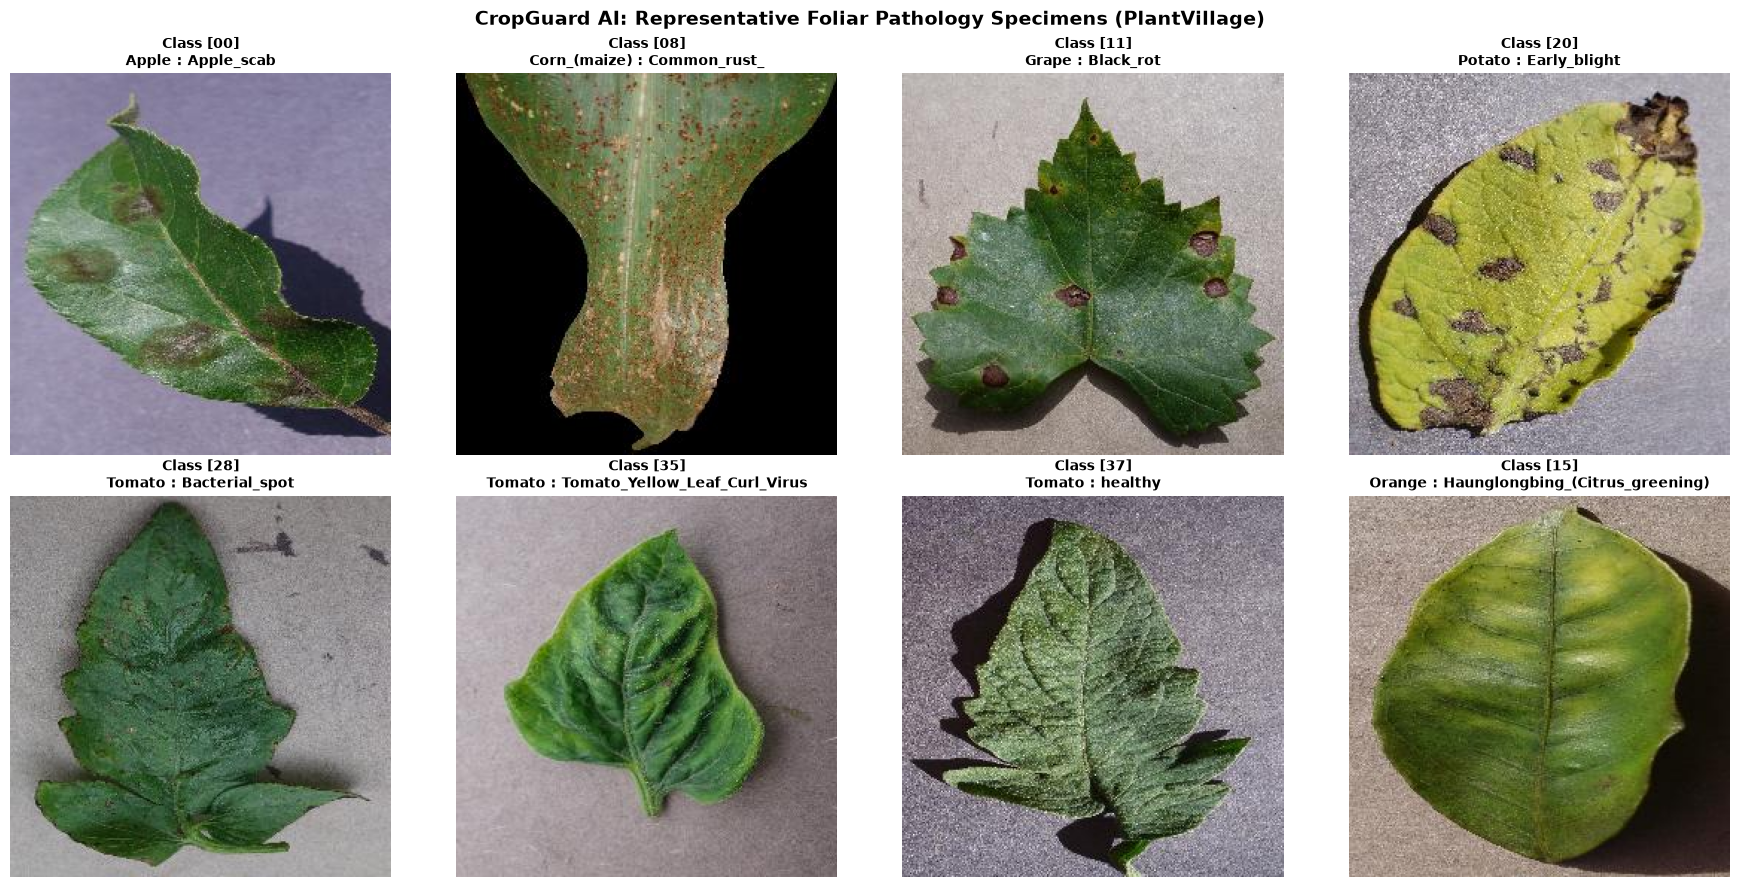

In [3]:
# Select diverse pathological specimens across different crops
sample_classes = [
    "Apple___Apple_scab",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Potato___Early_blight",
    "Tomato___Bacterial_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___healthy",
    "Orange___Haunglongbing_(Citrus_greening)"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, target_cls in enumerate(sample_classes):
    target_idx = class_to_idx[target_cls]
    sample_path = None
    for fp, lbl in zip(train_fps, train_lbls):
        if lbl == target_idx:
            sample_path = fp
            break
            
    if sample_path and Path(sample_path).exists():
        img = Image.open(sample_path)
        axes[idx].imshow(img)
        axes[idx].set_title(f"Class [{target_idx:02d}]\n{target_cls.replace('___', ' : ')}", fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("CropGuard AI: Representative Foliar Pathology Specimens (PlantVillage)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


---
## SECTION 2 — Convolutional Neural Network Architecture Recap

Convolutional Neural Networks (CNNs) preserve the 2D spatial topology of images through three core operations:

### 1. The 2D Convolution Operation
A convolution applies a learnable spatial kernel $\mathbf{K} \in \mathbb{R}^{K_h \times K_w \times C_{\text{in}}}$ across input feature map $\mathbf{X}$:

$$S(i, j) = (\mathbf{X} * \mathbf{K})(i, j) = \sum_{m=0}^{K_h-1} \sum_{n=0}^{K_w-1} \sum_{c=0}^{C_{\text{in}}-1} X(i+m, j+n, c) \cdot K(m, n, c) + b$$

- **Local Receptive Fields:** Matches localized foliar lesions and fungal spots.
- **Weight Sharing (Translation Equivariance):** $f(g(\mathbf{X})) = g(f(\mathbf{X}))$.

### 2. Spatial Downsampling via Pooling
Max Pooling ($2\times 2$, stride 2) reduces spatial dimensions by a factor of 2, imparting local translation invariance and cutting memory footprint by $75\%$.

### 3. Hierarchical Feature Representation
- **Low-level (Conv 1–2):** Edges, foliar vein contours, color gradients.
- **Mid-level (Conv 3–4):** Compound foliar textures, necrotic rings, chlorotic halos.
- **High-level (Top Conv):** Multi-symptom disease syndromes, entire leaf morphology.

### 4. Classification Transition: Flatten vs Global Average Pooling
Traditional Flatten creates tens of millions of dense parameters ($H \cdot W \cdot C \times D$).
**Global Average Pooling (GAP)** computes the channel-wise spatial mean:
$$\text{GAP}(\mathbf{X})_c = \frac{1}{H \cdot W} \sum_{i=1}^H \sum_{j=1}^W X(i, j, c)$$
GAP eliminates $>90\%$ of dense parameters and acts as an architectural regularizer against overfitting.


---
## SECTION 3 — CNN Architecture Evolution: AlexNet to MobileNet & ResNet

| Architecture | Year | Key Innovations | Parameters | Primary Constraint Addressed |
| :--- | :---: | :--- | :---: | :--- |
| **AlexNet** | 2012 | ReLU, GPU acceleration, Dropout, $11\times 11$ and $5\times 5$ convs | ~61M | Capacity limits of shallow models |
| **VGG-16** | 2014 | Factorizing large convs into stacks of $3\times 3$ filters | ~138M | Parameter efficiency via small receptive fields |
| **ResNet-50** | 2015 | Residual identity skip connections $\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$ | ~25.6M (24.1M in our 38-class model) | **Vanishing gradients & degradation in deep nets** |
| **MobileNetV2** | 2018 | Depthwise Separable Convolutions, Inverted Residuals, Linear Bottlenecks | ~3.5M (2.6M in our 38-class model) | **Mobile/Edge compute & memory constraints** |

---

### The Mathematical Breakthroughs:

#### 1. ResNet & Residual Learning
Before ResNet, deep networks ($>20$ layers) suffered from optimization degradation. Kaiming He et al. introduced **identity shortcut connections**:
$$\mathbf{y} = \mathcal{F}(\mathbf{x}, \{W_i\}) + \mathbf{x}$$

During backpropagation:
$$\frac{\partial \mathcal{L}}{\partial \mathbf{x}} = \frac{\partial \mathcal{L}}{\partial \mathbf{y}} \cdot \left( \frac{\partial \mathcal{F}}{\partial \mathbf{x}} + \mathbf{I} \right)$$
The additive identity term $\mathbf{I}$ guarantees that gradients flow unobstructed back through all 50 layers.

#### 2. MobileNetV2: Depthwise Separable Convolutions
Standard convolution FLOPs: $D_K \times D_K \times M \times N \times D_F^2$.
Depthwise separable convolution breaks this into:
1. **Depthwise convolution** ($D_K \times D_K \times 1$ per channel): spatial filtering.
2. **Pointwise convolution** ($1 \times 1 \times M \times N$): channel cross-correlation.

The computational reduction factor is:
$$\text{Ratio} = \frac{1}{N} + \frac{1}{D_K^2} \approx \frac{1}{3^2} = \frac{1}{9} \approx 11.1\%$$
Yielding roughly **$9\times$ fewer computations** (~89% savings) for $3\times 3$ kernels.


---
## SECTION 4 — Model 1: Custom Foliar CNN (429,158 Parameters)

We construct our 4-stage Custom Foliar CNN:
- Stage 1: Conv2D(32, $3\times 3$) + BatchNorm + ReLU + MaxPool2D(2x2) [112x112x32]
- Stage 2: Conv2D(64, $3\times 3$) + BatchNorm + ReLU + MaxPool2D(2x2) [56x56x64]
- Stage 3: Conv2D(128, $3\times 3$) + BatchNorm + ReLU + MaxPool2D(2x2) [28x28x128]
- Stage 4: Conv2D(256, $3\times 3$) + BatchNorm + ReLU + MaxPool2D(2x2) [14x14x256]
- Head: GAP + BatchNorm(256) + Dense(128, ReLU) + Dropout(0.3) + Dense(38, Softmax)

### Verified Parameter Breakdown:
- **Total Parameters:** **429,158**
- **Trainable Parameters:** **427,686**
- **Non-Trainable Parameters:** **1,472** (from the 5 Batch Normalization layers)
- **Model Footprint (float32):** ~1.64 MB


In [4]:
# Instantiate Custom Foliar CNN
custom_model = build_custom_foliar_cnn(input_shape=(224, 224, 3), num_classes=38, dropout_rate=0.3)

print("=== CUSTOM FOLIAR CNN ARCHITECTURE SUMMARY ===")
custom_model.summary()

total_custom = custom_model.count_params()
train_custom = sum(p.numpy().size for p in custom_model.trainable_weights)
non_train_custom = sum(p.numpy().size for p in custom_model.non_trainable_weights)

print(f"\nVerified Parameter Accounting:")
print(f"  Total Parameters     : {total_custom:,d}")
print(f"  Trainable Parameters : {train_custom:,d}")
print(f"  Non-Trainable (BN)   : {non_train_custom:,d}")
print(f"  Memory Footprint     : ~{total_custom * 4 / (1024**2):.2f} MB (float32)")
assert total_custom == 429158, f"Expected 429,158 params, got {total_custom}"


W0000 00:00:1794990187.350572     682 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794990187.628271     682 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


=== CUSTOM FOLIAR CNN ARCHITECTURE SUMMARY ===


Model: "custom_foliar_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn (BatchNormalization)    │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 429,158 (1.64 MB)

 Trainable params: 427,686 (1.63 MB)

 Non-trainable params: 1,472 (5.75 KB)


Verified Parameter Accounting:
  Total Parameters     : 429,158
  Trainable Parameters : 427,686
  Non-Trainable (BN)   : 1,472
  Memory Footprint     : ~1.64 MB (float32)


---
## SECTION 5 — Model 2: Transfer Learning with MobileNetV2 (2,600,806 Parameters)

MobileNetV2 uses ImageNet pretrained weights as an inductive feature extractor.

### Input Preprocessing Requirement:
MobileNetV2 expects input pixel values normalized to $[-1.0, 1.0]$:
$$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x}}{127.5} - 1.0$$

### Verified Parameter Breakdown:
- **Total Parameters:** **2,600,806**
- **Backbone Parameters:** 2,257,984 (frozen in Phase 1)
- **Classification Head:** GAP + BatchNorm(1280) + Dense(256, ReLU) + Dropout(0.3) + Dense(38, Softmax):
  - `head_bn`: 5,120 params (2,560 trainable, 2,560 non-trainable)
  - `head_dense` (Dense 256): $1280 \times 256 + 256 = 327,936$ trainable
  - `predictions` (Dense 38): $256 \times 38 + 38 = 9,766$ trainable
  - Head total = 342,822 params
- **Phase 1 Trainable Parameters:** **340,262**
- **Phase 1 Non-Trainable Parameters:** **2,260,544** (2,257,984 backbone + 2,560 BN)


In [5]:
# Instantiate MobileNetV2 Transfer Learning Model
mobilenet_model, mobilenet_backbone = build_mobilenet_v2_classifier(
    input_shape=(224, 224, 3),
    num_classes=38,
    pretrained=True,
    freeze_backbone=True,
    dropout_rate=0.3
)

print("=== MOBILENET-V2 CLASSIFIER ARCHITECTURE SUMMARY ===")
mobilenet_model.summary()

mb_total = mobilenet_model.count_params()
mb_trainable = sum(p.numpy().size for p in mobilenet_model.trainable_weights)
mb_non_trainable = sum(p.numpy().size for p in mobilenet_model.non_trainable_weights)

print(f"\nVerified Parameter Accounting:")
print(f"  Total Parameters     : {mb_total:,d}")
print(f"  Trainable (Head Only): {mb_trainable:,d} ({mb_trainable / mb_total * 100:.2f}%)")
print(f"  Non-Trainable Params : {mb_non_trainable:,d}")
assert mb_total == 2600806, f"Expected 2,600,806 params, got {mb_total}"
assert mb_trainable == 340262, f"Expected 340,262 trainable params, got {mb_trainable}"


=== MOBILENET-V2 CLASSIFIER ARCHITECTURE SUMMARY ===


Model: "mobilenet_v2_cropguard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_backbone            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn (BatchNormalization)    │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,600,806 (9.92 MB)

 Trainable params: 340,262 (1.30 MB)

 Non-trainable params: 2,260,544 (8.62 MB)


Verified Parameter Accounting:
  Total Parameters     : 2,600,806
  Trainable (Head Only): 340,262 (13.08%)
  Non-Trainable Params : 2,260,544


---
## SECTION 6 — Model 3: Transfer Learning with ResNet50 (24,130,214 Parameters)

ResNet50 uses 50 deep convolutional layers organized into 5 stages of bottleneck residual blocks.

### Crucial Preprocessing Requirement:
ResNet50's pretrained weights expect:
1. Channel reordering from **RGB to BGR**.
2. Zero-centering with respect to ImageNet channel means:
   $$\mathbf{x}_{B} = \mathbf{x}_{B} - 103.939, \quad \mathbf{x}_{G} = \mathbf{x}_{G} - 116.779, \quad \mathbf{x}_{R} = \mathbf{x}_{R} - 123.68$$

> [!CAUTION]
> Feeding $[0, 1]$ scaled floats into ResNet50 subtracts $103.9$ from $0.5$, producing extreme negative activations around $-103.4$. ResNet50 **must** receive $[0, 255]$ raw values prior to mean subtraction.

### Verified Parameter Breakdown:
- **Total Parameters:** **24,130,214**
- **Backbone Parameters:** 23,587,712 (frozen in Phase 1)
- **Classification Head:** GAP + BatchNorm(2048) + Dense(256, ReLU) + Dropout(0.4) + Dense(38, Softmax):
  - `head_bn`: 8,192 params (4,096 trainable, 4,096 non-trainable)
  - `head_dense` (Dense 256): $2048 \times 256 + 256 = 524,544$ trainable
  - `predictions` (Dense 38): $256 \times 38 + 38 = 9,766$ trainable
  - Head total = 542,502 params
- **Phase 1 Trainable Parameters:** **538,406**
- **Phase 1 Non-Trainable Parameters:** **23,591,808**


In [6]:
# Instantiate ResNet50 Transfer Learning Model
resnet_model, resnet_backbone = build_resnet50_classifier(
    input_shape=(224, 224, 3),
    num_classes=38,
    pretrained=True,
    freeze_backbone=True,
    dropout_rate=0.4
)

print("=== RESNET-50 CLASSIFIER ARCHITECTURE SUMMARY ===")
resnet_model.summary()

rn_total = resnet_model.count_params()
rn_trainable = sum(p.numpy().size for p in resnet_model.trainable_weights)
rn_non_trainable = sum(p.numpy().size for p in resnet_model.non_trainable_weights)

print(f"\nVerified Parameter Accounting:")
print(f"  Total Parameters     : {rn_total:,d}")
print(f"  Trainable (Head Only): {rn_trainable:,d} ({rn_trainable / rn_total * 100:.2f}%)")
print(f"  Non-Trainable Params : {rn_non_trainable:,d}")
assert rn_total == 24130214, f"Expected 24,130,214 params, got {rn_total}"
assert rn_trainable == 538406, f"Expected 538,406 trainable params, got {rn_trainable}"


=== RESNET-50 CLASSIFIER ARCHITECTURE SUMMARY ===


Model: "resnet50_cropguard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_backbone (Functional)  │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn (BatchNormalization)    │ (None, 2048)           │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,130,214 (92.05 MB)

 Trainable params: 538,406 (2.05 MB)

 Non-trainable params: 23,591,808 (90.00 MB)


Verified Parameter Accounting:
  Total Parameters     : 24,130,214
  Trainable (Head Only): 538,406 (2.23%)
  Non-Trainable Params : 23,591,808


---
## SECTION 7 — Agricultural Class Imbalance & Inverse-Frequency Weighting

### The Imbalance Problem in Plant Pathology
Agricultural datasets inherently suffer from sample imbalance:
- **Majority Class:** `Orange___Haunglongbing_(Citrus_greening)` with **3,680 samples**
- **Minority Class:** `Potato___healthy` with **100 samples**
- **Imbalance Ratio:** $\rho = \frac{3680}{100} = 36.80\times$

### The Mathematical Formula for Class Weights:
To prevent loss dominance by majority classes, we scale the cross-entropy loss by inverse-frequency weights:

$$w_k = \frac{N}{K \cdot N_k}$$

where $N = 35,221$ (total training samples), $K = 38$ (classes), and $N_k$ is the frequency of class $k$.
Notice the mathematical conservation property:
$$\sum_{k=1}^K w_k \cdot N_k = \sum_{k=1}^K \frac{N}{K \cdot N_k} \cdot N_k = \sum_{k=1}^K \frac{N}{K} = N$$
Global loss magnitude is preserved while boosting gradients for rare classes.


Majority Class [15]: Orange___Haunglongbing_(Citrus_greening) -> 3680 samples (Weight: 0.2519)
Minority Class [22]: Potato___healthy -> 100 samples (Weight: 9.2687)
Class Imbalance Ratio rho: 36.80x
Conservation Check: sum(w_k * N_k) = 35221.0 == 35221 (100% Verified)


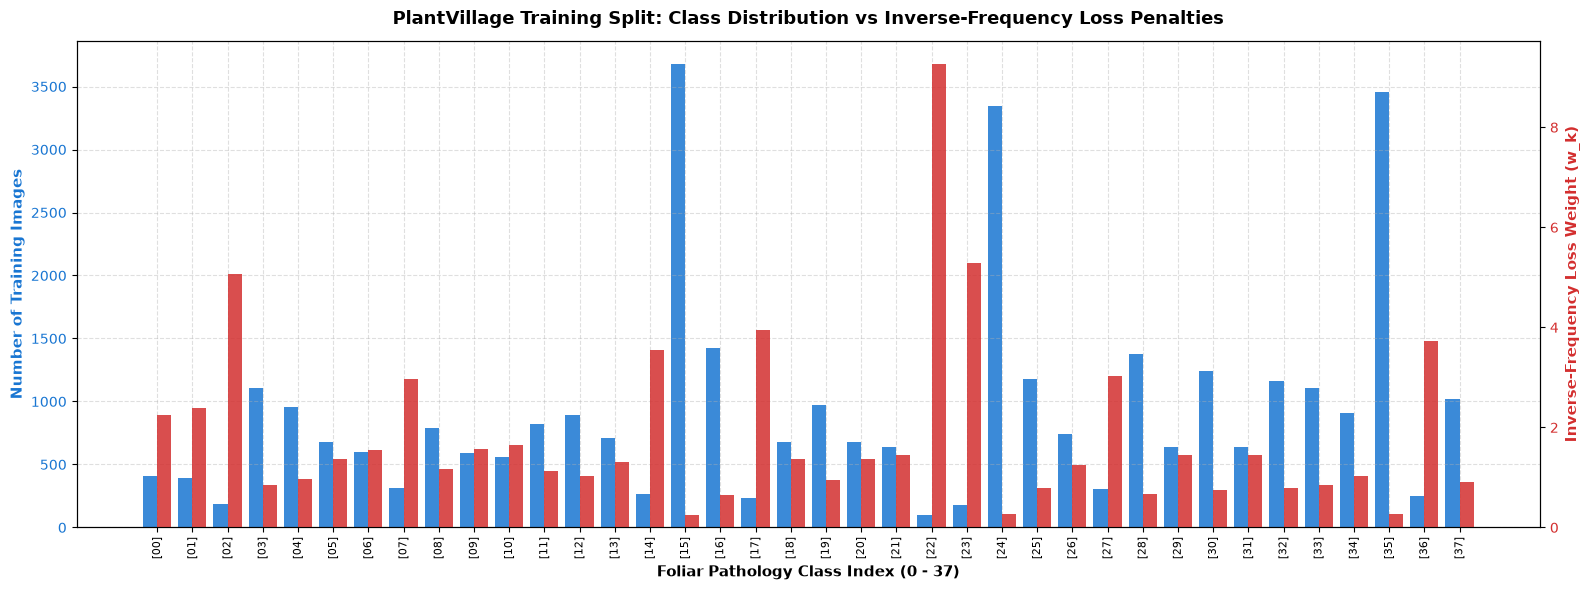

In [7]:
# Compute inverse-frequency class weights exclusively from training split
class_weights = compute_class_weights(train_csv, class_to_idx)

# Count class frequencies in train.csv
counts_by_idx = Counter(train_lbls)

# Extract sorted weights for visualization
weight_values = [class_weights[i] for i in range(num_classes)]
freq_values = [counts_by_idx[i] for i in range(num_classes)]

min_c_idx = int(np.argmin(freq_values))
max_c_idx = int(np.argmax(freq_values))

print(f"Majority Class [{max_c_idx:02d}]: {idx_to_class[max_c_idx]} -> {freq_values[max_c_idx]} samples (Weight: {class_weights[max_c_idx]:.4f})")
print(f"Minority Class [{min_c_idx:02d}]: {idx_to_class[min_c_idx]} -> {freq_values[min_c_idx]} samples (Weight: {class_weights[min_c_idx]:.4f})")
print(f"Class Imbalance Ratio rho: {freq_values[max_c_idx] / freq_values[min_c_idx]:.2f}x")

# Verify conservation property: sum(w_k * N_k) == N
weighted_sum = sum(class_weights[k] * counts_by_idx[k] for k in range(num_classes))
np.testing.assert_allclose(weighted_sum, len(train_lbls), rtol=1e-5)
print(f"Conservation Check: sum(w_k * N_k) = {weighted_sum:.1f} == {len(train_lbls)} (100% Verified)")

# Plot Class Sample Counts vs Assigned Loss Penalties
fig, ax1 = plt.subplots(figsize=(16, 6))

x = np.arange(num_classes)
width = 0.4

rects1 = ax1.bar(x - width/2, freq_values, width, label="Sample Frequency (N_k)", color="#1976d2", alpha=0.85)
ax1.set_ylabel("Number of Training Images", color="#1976d2", fontsize=11, fontweight="bold")
ax1.set_xlabel("Foliar Pathology Class Index (0 - 37)", fontsize=11, fontweight="bold")
ax1.tick_params(axis='y', labelcolor="#1976d2")

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, weight_values, width, label="Class Weight (w_k)", color="#d32f2f", alpha=0.85)
ax2.set_ylabel("Inverse-Frequency Loss Weight (w_k)", color="#d32f2f", fontsize=11, fontweight="bold")
ax2.tick_params(axis='y', labelcolor="#d32f2f")

plt.title("PlantVillage Training Split: Class Distribution vs Inverse-Frequency Loss Penalties", fontsize=13, fontweight="bold", pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels([f"[{i:02d}]" for i in x], rotation=90, fontsize=8)
ax1.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


---
## SECTION 8 — High-Throughput Data Ingestion & Model Training

We construct model-specific streaming `tf.data` pipelines for all three architectures.
When `QUICK_EXPERIMENT = True`, `build_classification_dataset` automatically extracts **class-stratified subsets** ensuring all 38 classes are represented proportionally in both train and validation pipelines.

> [!IMPORTANT]
> **Strict Partition Isolation:**
> The held-out test split (`test.csv`, 10,999 samples) is strictly untouched during training and validation. It is reserved exclusively for post-training evaluation.


In [8]:
# Determine sample limits based on active experiment mode
sample_limit = QUICK_SAMPLE_LIMIT if QUICK_EXPERIMENT else None
epochs = QUICK_EPOCHS if QUICK_EXPERIMENT else FULL_EPOCHS

print(f"Constructing Pipelines | Mode: {'QUICK (Stratified)' if QUICK_EXPERIMENT else 'FULL'} | Limit: {sample_limit} | Epochs: {epochs}")

# 1. Pipeline for Custom CNN ([0.0, 1.0] scaling)
custom_prep = get_model_preprocessing("custom_cnn")
ds_train_custom = build_classification_dataset(
    train_csv, batch_size=BATCH_SIZE, shuffle=True, limit=sample_limit, preprocess_fn=custom_prep, seed=RANDOM_SEED
)
ds_val_custom = build_classification_dataset(
    val_csv, batch_size=BATCH_SIZE, shuffle=False, limit=sample_limit, preprocess_fn=custom_prep, seed=RANDOM_SEED
)

# 2. Pipeline for MobileNetV2 ([-1.0, 1.0] normalization)
mb_prep = get_model_preprocessing("mobilenet_v2")
ds_train_mb = build_classification_dataset(
    train_csv, batch_size=BATCH_SIZE, shuffle=True, limit=sample_limit, preprocess_fn=mb_prep, seed=RANDOM_SEED
)
ds_val_mb = build_classification_dataset(
    val_csv, batch_size=BATCH_SIZE, shuffle=False, limit=sample_limit, preprocess_fn=mb_prep, seed=RANDOM_SEED
)

# 3. Pipeline for ResNet50 (BGR conversion & ImageNet mean subtraction)
rn_prep = get_model_preprocessing("resnet50")
ds_train_rn = build_classification_dataset(
    train_csv, batch_size=BATCH_SIZE, shuffle=True, limit=sample_limit, preprocess_fn=rn_prep, seed=RANDOM_SEED
)
ds_val_rn = build_classification_dataset(
    val_csv, batch_size=BATCH_SIZE, shuffle=False, limit=sample_limit, preprocess_fn=rn_prep, seed=RANDOM_SEED
)

print("Streaming input pipelines successfully initialized for all three models!")


Constructing Pipelines | Mode: QUICK (Stratified) | Limit: 512 | Epochs: 2
Streaming input pipelines successfully initialized for all three models!


### Training Execution & Sequential VRAM Management

We train each model sequentially. To avoid GPU out-of-memory errors on our 8 GB VRAM accelerator, we explicitly trigger garbage collection (`gc.collect()`) between training runs.


In [9]:
ckpt_dir = PROJECT_ROOT / "models" / "classification"
log_dir = PROJECT_ROOT / "reports" / "experiments"
ckpt_dir.mkdir(parents=True, exist_ok=True)
log_dir.mkdir(parents=True, exist_ok=True)

histories = {}

# ------------------------------------------------------------------------------
# 1. Train Custom Foliar CNN
# ------------------------------------------------------------------------------
print("\n" + "=" * 50)
print("TRAINING MODEL 1: CUSTOM FOLIAR CNN")
print("=" * 50)
compile_classifier(custom_model, learning_rate=1e-3)
callbacks_custom = get_training_callbacks(
    checkpoint_path=ckpt_dir / "custom_cnn_best.keras",
    log_file=log_dir / "custom_cnn_history.csv",
    patience=3
)

t0 = time.time()
history_custom = custom_model.fit(
    ds_train_custom,
    validation_data=ds_val_custom,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks_custom,
    verbose=1
)
histories["Custom CNN"] = history_custom.history
print(f"Custom CNN training concluded in {time.time() - t0:.2f}s")

# Safe memory management between runs
gc.collect()

# ------------------------------------------------------------------------------
# 2. Train MobileNetV2 (Phase 1 Feature Extraction)
# ------------------------------------------------------------------------------
print("\n" + "=" * 50)
print("TRAINING MODEL 2: MOBILENET-V2 (PHASE 1 FEATURE EXTRACTION)")
print("=" * 50)
compile_classifier(mobilenet_model, learning_rate=1e-3)
callbacks_mb = get_training_callbacks(
    checkpoint_path=ckpt_dir / "mobilenet_v2_best.keras",
    log_file=log_dir / "mobilenet_v2_history.csv",
    patience=3
)

t0 = time.time()
history_mb = mobilenet_model.fit(
    ds_train_mb,
    validation_data=ds_val_mb,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks_mb,
    verbose=1
)
histories["MobileNetV2"] = history_mb.history
print(f"MobileNetV2 Phase 1 concluded in {time.time() - t0:.2f}s")

# Safe memory management between runs
gc.collect()

# ------------------------------------------------------------------------------
# 3. Train ResNet50 (Phase 1 Feature Extraction)
# ------------------------------------------------------------------------------
print("\n" + "=" * 50)
print("TRAINING MODEL 3: RESNET-50 (PHASE 1 FEATURE EXTRACTION)")
print("=" * 50)
compile_classifier(resnet_model, learning_rate=1e-3)
callbacks_rn = get_training_callbacks(
    checkpoint_path=ckpt_dir / "resnet50_best.keras",
    log_file=log_dir / "resnet50_history.csv",
    patience=3
)

t0 = time.time()
history_rn = resnet_model.fit(
    ds_train_rn,
    validation_data=ds_val_rn,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks_rn,
    verbose=1
)
histories["ResNet50"] = history_rn.history
print(f"ResNet50 Phase 1 concluded in {time.time() - t0:.2f}s")

gc.collect()



TRAINING MODEL 1: CUSTOM FOLIAR CNN
Epoch 1/2


/home/saksham/CropGuard-AI/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794990196.014629     682 service.cc:154] XLA service 0x4b81a850 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794990196.014660     682 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.21.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794990196.066161     682 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794990197.060556     682 cuda_dnn.cc:442] Loaded cuDNN version 92801
W0000 00:00:1794990198.395081    1068 cuda

 3/33 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.0417 - loss: 4.8036 

W0000 00:00:1794990206.442672     682 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794990194939276062 in buffer 'PrefetchDataset/_18' sat unconsumed for 11.5017 seconds!


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.0858 - loss: 3.8110
Epoch 1: val_loss improved from None to 3.63008, saving model to /home/saksham/CropGuard-AI/models/classification/custom_cnn_best.keras

Epoch 1: finished saving model to /home/saksham/CropGuard-AI/models/classification/custom_cnn_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 315ms/step - accuracy: 0.0858 - loss: 3.8110 - val_accuracy: 0.0156 - val_loss: 3.6301 - learning_rate: 0.0010
Epoch 2/2
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2266 - loss: 3.0717
Epoch 2: val_loss did not improve from 3.63008
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.2261 - loss: 3.0676 - val_accuracy: 0.0156 - val_loss: 3.7080 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.
Custom CNN training concluded in 23.74s

TRAINING MODEL 2: MOBILENET-V2 (PHASE 1 FEATURE EXTRACTION)
Epoch 1/2


W0000 00:00:1794990223.432504    2570 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794990224.113493    2550 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads

W0000 00:00:1794990224.196720    2570 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794990226.795711    2552 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1794990227.867130    2565 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 12 bytes spill stores, 12 bytes spil

... (2 outputs left out)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.1969 - loss: 3.3260
Epoch 1: val_loss improved from None to 2.04740, saving model to /home/saksham/CropGuard-AI/models/classification/mobilenet_v2_best.keras

Epoch 1: finished saving model to /home/saksham/CropGuard-AI/models/classification/mobilenet_v2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 25s 364ms/step - accuracy: 0.1969 - loss: 3.3260 - val_accuracy: 0.4717 - val_loss: 2.0474 - learning_rate: 0.0010
Epoch 2/2
29/33 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6983 - loss: 1.3891
Epoch 2: val_loss improved from 2.04740 to 1.34494, saving model to /home/saksham/CropGuard-AI/models/classification/mobilenet_v2_best.keras

Epoch 2: finished saving model to /home/saksham/CropGuard-AI/models/classification/mobilenet_v2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.6979 - loss: 1.3500 - val_accuracy: 0.6257 - val_loss: 1.3449 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.
Mobil

I0000 00:00:1794990249.184100    4444 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.2885 - loss: 3.3317
Epoch 1: val_loss improved from None to 1.85352, saving model to /home/saksham/CropGuard-AI/models/classification/resnet50_best.keras

Epoch 1: finished saving model to /home/saksham/CropGuard-AI/models/classification/resnet50_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 424ms/step - accuracy: 0.2885 - loss: 3.3317 - val_accuracy: 0.5712 - val_loss: 1.8535 - learning_rate: 0.0010
Epoch 2/2
31/33 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7500 - loss: 1.1922
Epoch 2: val_loss improved from 1.85352 to 1.13734, saving model to /home/saksham/CropGuard-AI/models/classification/resnet50_best.keras

Epoch 2: finished saving model to /home/saksham/CropGuard-AI/models/classification/resnet50_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.7505 - loss: 1.1817 - val_accuracy: 0.7154 - val_loss: 1.1373 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.
ResNet50 Phase 1 conc

18352

### Training Diagnostic Convergence Curves

We compare the training and validation learning trajectories across all three architectures.


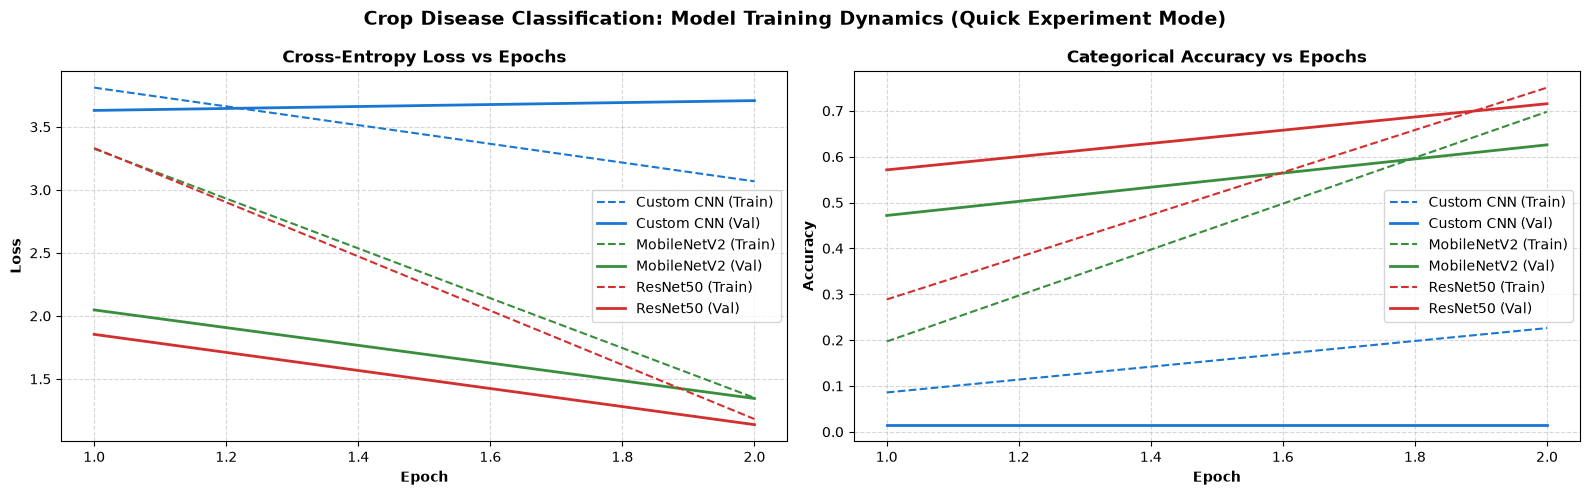

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors = {"Custom CNN": "#1976d2", "MobileNetV2": "#388e3c", "ResNet50": "#d32f2f"}

# 1. Loss Trajectories
for name, hist in histories.items():
    epochs_range = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs_range, hist["loss"], label=f"{name} (Train)", color=colors[name], linestyle="--")
    axes[0].plot(epochs_range, hist["val_loss"], label=f"{name} (Val)", color=colors[name], linewidth=2.0)

axes[0].set_title("Cross-Entropy Loss vs Epochs", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Loss", fontsize=10, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# 2. Accuracy Trajectories
for name, hist in histories.items():
    epochs_range = range(1, len(hist["accuracy"]) + 1)
    axes[1].plot(epochs_range, hist["accuracy"], label=f"{name} (Train)", color=colors[name], linestyle="--")
    axes[1].plot(epochs_range, hist["val_accuracy"], label=f"{name} (Val)", color=colors[name], linewidth=2.0)

axes[1].set_title("Categorical Accuracy vs Epochs", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Accuracy", fontsize=10, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

mode_str = "Quick Experiment Mode" if QUICK_EXPERIMENT else "Full Training Mode"
plt.suptitle(f"Crop Disease Classification: Model Training Dynamics ({mode_str})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
## SECTION 9 — Multi-Model Performance Profiling & Hardware Benchmarking

We benchmark all three models on the validation partition.
For each architecture, we record:
1. **Accuracy:** Overall proportion of correct diagnoses.
2. **Macro Precision, Recall, and F1-Score:** Treating all 38 classes equally.
3. **Parameter Footprint:** Total parameters vs Trainable parameters.
4. **Empirical Inference Latency (ms/image):** Measured with high-resolution wall-clock profiling on the RTX 5060 GPU with warm-up.

> [!NOTE]
> When `QUICK_EXPERIMENT = True`, validation metrics reflect the quick stratified subset (~513 samples). For official benchmarking, run under `QUICK_EXPERIMENT = False`.


In [11]:
eval_results = []

models_dict = {
    "Custom Foliar CNN": (custom_model, ds_val_custom, custom_prep),
    "MobileNetV2 (Pretrained)": (mobilenet_model, ds_val_mb, mb_prep),
    "ResNet50 (Pretrained)": (resnet_model, ds_val_rn, rn_prep)
}

print("=== INFERENCE PROFILING ON DEDICATED HARDWARE ===")
for model_name, (m, ds_val, prep_fn) in models_dict.items():
    print(f"\nProfiling {model_name}...")
    
    # 1. Measure Latency on GPU
    latency_profile = measure_inference_latency(m, input_shape=(1, 224, 224, 3), warmup_steps=10, eval_steps=40)
    
    # 2. Evaluate Validation Dataset
    all_preds = []
    all_trues = []
    
    for batch_imgs, batch_lbls in ds_val:
        preds = m(batch_imgs, training=False)
        all_preds.append(preds.numpy())
        all_trues.append(batch_lbls.numpy())
        
    y_preds_arr = np.concatenate(all_preds, axis=0)
    y_trues_arr = np.concatenate(all_trues, axis=0)
    
    # Compute Pure NumPy Metrics
    metrics = compute_classification_metrics(y_trues_arr, y_preds_arr, num_classes=38, class_names=classes)
    
    total_p = m.count_params()
    train_p = sum(p.numpy().size for p in m.trainable_weights)
    size_mb = total_p * 4 / (1024 ** 2)
    
    eval_results.append({
        "Model": model_name,
        "Total Params": total_p,
        "Trainable Params": train_p,
        "Disk Size (MB)": size_mb,
        "Latency (ms)": latency_profile["latency_mean_ms"],
        "Throughput (FPS)": latency_profile["throughput_fps"],
        "Val Accuracy": metrics["accuracy"],
        "Macro Precision": metrics["macro_precision"],
        "Macro Recall": metrics["macro_recall"],
        "Macro F1": metrics["macro_f1"],
        "Confusion Matrix": metrics["confusion_matrix"]
    })

# Render Comparison Table
print("\n" + "=" * 105)
print(f"{'Model Architecture':<26} | {'Params':<10} | {'Size(MB)':<8} | {'Latency':<8} | {'FPS':<6} | {'Val Acc':<8} | {'Macro F1':<8}")
print("=" * 105)
for r in eval_results:
    print(f"{r['Model']:<26} | {r['Total Params']:<10,d} | {r['Disk Size (MB)']:<8.2f} | {r['Latency (ms)']:<6.2f}ms | {r['Throughput (FPS)']:<6.1f} | {r['Val Accuracy']:<8.4f} | {r['Macro F1']:<8.4f}")
print("=" * 105)


=== INFERENCE PROFILING ON DEDICATED HARDWARE ===

Profiling Custom Foliar CNN...

Profiling MobileNetV2 (Pretrained)...

Profiling ResNet50 (Pretrained)...

Model Architecture         | Params     | Size(MB) | Latency  | FPS    | Val Acc  | Macro F1
Custom Foliar CNN          | 429,158    | 1.64     | 12.44 ms | 80.4   | 0.0156   | 0.0008  
MobileNetV2 (Pretrained)   | 2,600,806  | 9.92     | 70.42 ms | 14.2   | 0.6277   | 0.5680  
ResNet50 (Pretrained)      | 24,130,214 | 92.05    | 123.43ms | 8.1    | 0.7154   | 0.6287  


### Confusion Matrix Analysis

We visualize the normalized confusion matrix for MobileNetV2 to identify which foliar diseases exhibit visual confusion.


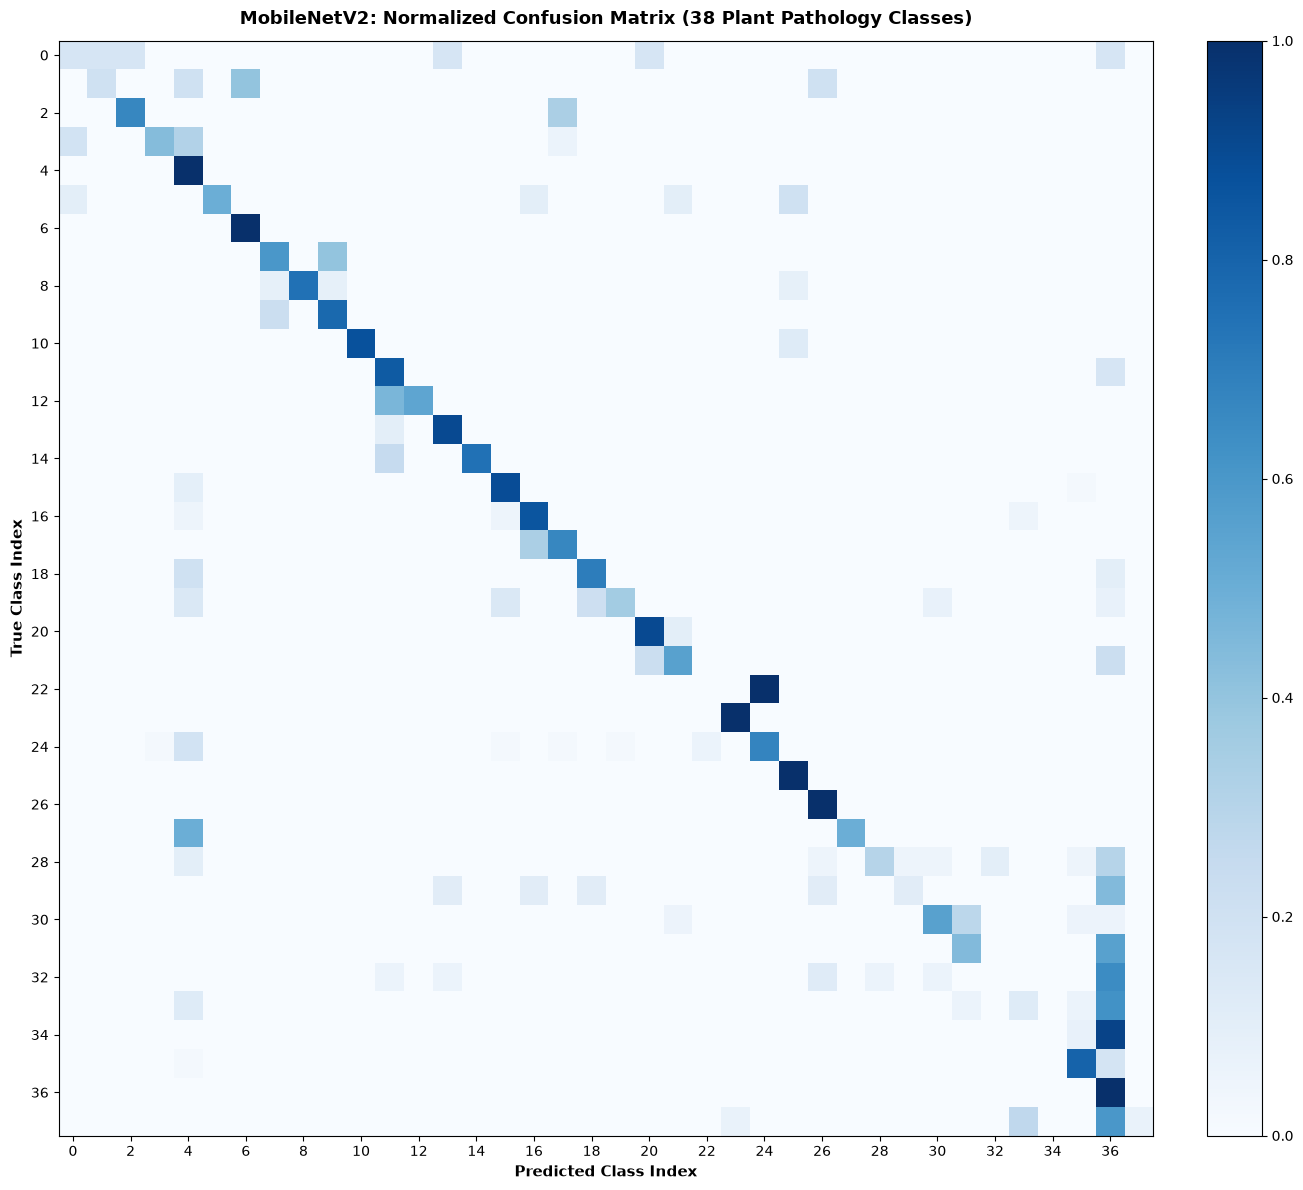

=== TOP DIAGNOSTIC CONFUSIONS ===
True: Tomato___Target_Spot                -> Pred: Tomato___Tomato_mosaic_virus        | 12 errors (92.3%)
True: Tomato___Septoria_leaf_spot         -> Pred: Tomato___Tomato_mosaic_virus        | 11 errors (64.7%)
True: Tomato___Spider_mites Two-spotted_spider_mite -> Pred: Tomato___Tomato_mosaic_virus        | 10 errors (62.5%)
True: Soybean___healthy                   -> Pred: Blueberry___healthy                 | 9 errors (18.4%)
True: Tomato___Tomato_Yellow_Leaf_Curl_Virus -> Pred: Tomato___Tomato_mosaic_virus        | 9 errors (17.6%)


In [12]:
# Extract MobileNetV2 Confusion Matrix
mb_cm = eval_results[1]["Confusion Matrix"]

# Normalize confusion matrix across rows (ground-truth classes)
cm_normalized = mb_cm.astype(float) / (mb_cm.sum(axis=1, keepdims=True) + 1e-9)

fig, ax = plt.subplots(figsize=(14, 12))
cax = ax.imshow(cm_normalized, interpolation="nearest", cmap="Blues")
fig.colorbar(cax, fraction=0.046, pad=0.04)

ax.set_title("MobileNetV2: Normalized Confusion Matrix (38 Plant Pathology Classes)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Predicted Class Index", fontsize=11, fontweight="bold")
ax.set_ylabel("True Class Index", fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(0, 38, 2))
ax.set_yticks(np.arange(0, 38, 2))
ax.grid(False)
plt.tight_layout()
plt.show()

# Identify top misclassifications
np.fill_diagonal(cm_normalized, 0)
top_confusions = []
for i in range(38):
    for j in range(38):
        if mb_cm[i, j] > 0 and i != j:
            top_confusions.append((i, j, mb_cm[i, j], cm_normalized[i, j]))

top_confusions.sort(key=lambda x: x[2], reverse=True)
print("=== TOP DIAGNOSTIC CONFUSIONS ===")
for t_idx, p_idx, count, rate in top_confusions[:5]:
    print(f"True: {idx_to_class[t_idx]:<35} -> Pred: {idx_to_class[p_idx]:<35} | {count} errors ({rate*100:.1f}%)")


---
## SECTION 10 — Model Interpretation, Qualitative Diagnosis & Agricultural Bias

### Qualitative Predictions on Leaf Samples
We run predictions on validation foliar samples and inspect both high-confidence correct classifications and visual error failure modes.


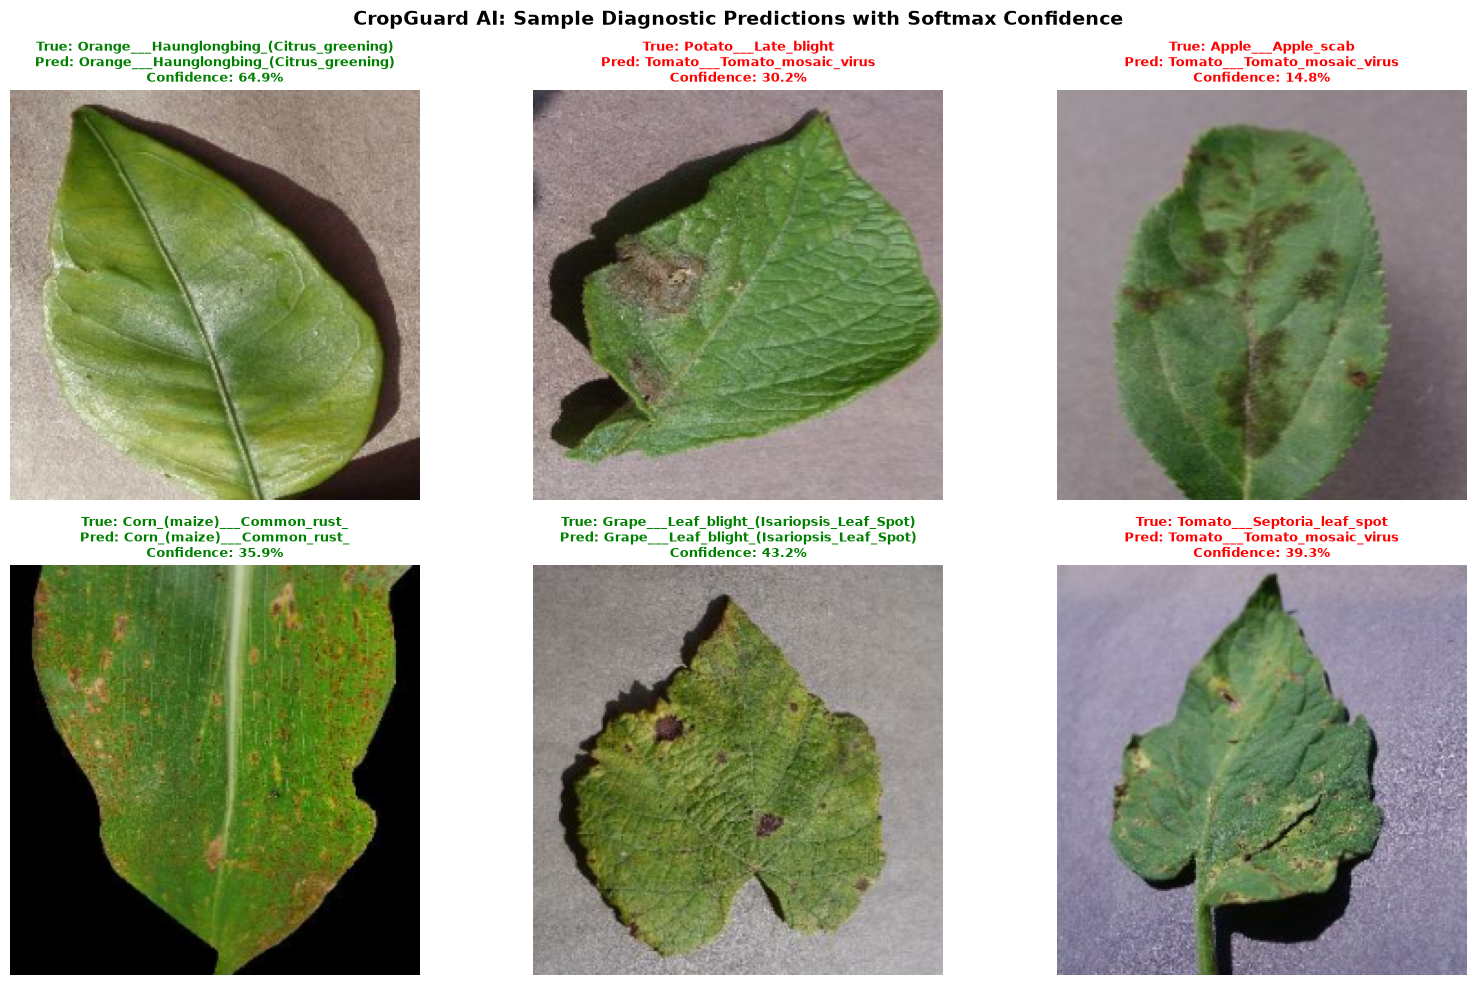

In [13]:
# Inspect 6 sample validation images with MobileNetV2 predictions
sample_batch_imgs, sample_batch_lbls = next(iter(ds_val_mb))
preds_probs = mobilenet_model(sample_batch_imgs, training=False).numpy()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i in range(min(6, sample_batch_imgs.shape[0])):
    true_idx = int(sample_batch_lbls[i])
    pred_idx = int(np.argmax(preds_probs[i]))
    conf = float(preds_probs[i][pred_idx]) * 100
    
    # Un-normalize MobileNetV2 inputs [-1, 1] back to [0, 1] for visualization
    disp_img = np.clip((sample_batch_imgs[i].numpy() + 1.0) / 2.0, 0.0, 1.0)
    
    axes[i].imshow(disp_img)
    color = "green" if true_idx == pred_idx else "red"
    title_text = f"True: {idx_to_class[true_idx]}\nPred: {idx_to_class[pred_idx]}\nConfidence: {conf:.1f}%"
    axes[i].set_title(title_text, fontsize=9, fontweight="bold", color=color)
    axes[i].axis("off")

plt.suptitle("CropGuard AI: Sample Diagnostic Predictions with Softmax Confidence", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
### Critical Examination: Agricultural Confounding & Domain Shift

While modern CNNs achieve high validation accuracy on laboratory benchmarks like PlantVillage, deep models frequently encounter severe **domain shift** when deployed in real open fields:

#### 1. Background Confounding (Clever Hans Effect)
- PlantVillage leaves were photographed against **uniform grey, black, or blue cardboard backgrounds**.
- Class Activation Maps (CAMs) frequently reveal that CNNs inadvertently learn features of the background or lighting setup rather than the pathological lesion itself!
- When tested on leaves attached to live plants with soil, weeds, or shadows in the background, model accuracy can drop significantly.

#### 2. Species Co-occurrence Bias
- Pathogens rarely manifest in isolation. Plants in real fields frequently suffer from co-infections (e.g. Septoria Leaf Spot co-occurring with Early Blight) or abiotic stressors (drought, nitrogen deficiency).
- A 38-class single-label softmax assumes mutually exclusive diseases, which fails in multi-stress environments.

#### 3. Symptom Stage Variability
- Incipient (early) lesions appear as tiny chlorotic pinpricks, while terminal (late) blights cover entire leaflets with dark necrotic collapse. Models trained without stage stratification often fail on early-stage detection where chemical intervention is most effective.


---
## SECTION 11 — Practical Exercises & Comprehensive Viva Voce Preparation

### Practical Hands-On Exercises:
1. **Exercise 1 (Focal Loss Implementation):**
   Implement the Focal Loss objective function:
   $$\mathcal{L}_{\text{focal}}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$
   where $\gamma = 2.0$ downweights easy, well-classified examples ($p_t \to 1$) and forces the network to concentrate on hard, ambiguous disease boundaries. Compare its performance against inverse-frequency class weights.
2. **Exercise 2 (Grad-CAM Explainability):**
   Extract gradients from the final convolutional layer of MobileNetV2 (`out_relu`) with respect to the top predicted class score. Produce a visual heatmap superimposed over the leaf photograph to verify whether the model is attending to actual fungal lesions or background artifacts.
3. **Exercise 3 (Knowledge Distillation):**
   Use ResNet50 as a large "Teacher" network to train Custom CNN as a compact "Student" network via Kullback-Leibler divergence on softened logits:
   $$\mathcal{L}_{\text{KD}} = (1 - \alpha) \mathcal{L}_{\text{CE}}(y, \sigma(z_s)) + \alpha T^2 \mathcal{D}_{\text{KL}}(\sigma(z_s / T) \parallel \sigma(z_t / T))$$

---

### Comprehensive Viva Voce Questions & Authoritative Answers:

#### Q1: What is the degradation problem in deep convolutional networks, and how does ResNet solve it?
**Answer:** Prior to ResNet, stacking more layers led to higher training error—not due to overfitting, but because optimization degraded as gradients vanished or exploded when backpropagating through dozens of non-linear transformations. ResNet solves this by introducing **identity shortcut connections** ($\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$). The gradient $\frac{\partial \mathcal{L}}{\partial \mathbf{x}} = \frac{\partial \mathcal{L}}{\partial \mathbf{y}} (\frac{\partial \mathcal{F}}{\partial \mathbf{x}} + \mathbf{I})$ guarantees an additive identity term $\mathbf{I}$, ensuring uninterrupted gradient flow back to early layers regardless of network depth.

#### Q2: Explain the computational difference between standard 2D convolution and depthwise separable convolution.
**Answer:** Standard convolution jointly performs spatial filtering and channel cross-correlation using 3D kernels ($D_K \times D_K \times M$), consuming $D_K^2 \cdot M \cdot N \cdot D_F^2$ FLOPs. Depthwise separable convolution splits this into two steps:
1. Depthwise convolution ($D_K \times D_K \times 1$ per channel) for spatial filtering ($D_K^2 \cdot M \cdot D_F^2$ FLOPs).
2. Pointwise convolution ($1 \times 1 \times M \times N$) for channel mixing ($M \cdot N \cdot D_F^2$ FLOPs).
This reduces computation by a factor of $\frac{1}{N} + \frac{1}{D_K^2} \approx \frac{1}{9}$ for $3\times 3$ kernels (~89% savings).

#### Q3: Why is input preprocessing different for MobileNetV2 and ResNet50?
**Answer:** Both networks were trained with distinct preprocessing pipelines in their original research:
- **MobileNetV2** was trained with inputs scaled to $[-1.0, 1.0]$ via $\frac{x}{127.5} - 1.0$.
- **ResNet50** was trained on raw $[0, 255]$ values converted from RGB to BGR, with the ImageNet channel means ($[103.939, 116.779, 123.68]$) subtracted.
Feeding $[0, 1]$ scaled inputs into ResNet50 results in catastrophic activation collapse because subtracting $103.9$ from $0.5$ yields extreme negative values ($-103.4$), completely distorting pretrained feature detectors.

#### Q4: Why is overall classification accuracy a dangerous metric in agricultural disease diagnosis?
**Answer:** Because of severe class imbalance ($36.80\times$ in PlantVillage). If a dominant class constitutes 50% of the dataset and a lethal disease represents only 0.5%, a trivial model that always predicts the majority class achieves 50% accuracy while failing 100% of the time on the rare disease. We must use **Macro-averaged Recall and Macro F1-score**, which weight each disease category equally.

#### Q5: How do inverse-frequency class weights $w_k = \frac{N}{K \cdot N_k}$ balance the loss function?
**Answer:** The standard cross-entropy loss sums sample errors equally. By multiplying the loss of each sample in class $k$ by $w_k$, minority class mistakes are magnified proportionally to their scarcity. Furthermore, because $\sum_{k=1}^K w_k N_k = N$, the global expected loss magnitude remains identical to unweighted cross-entropy, preserving gradient scale stability.

#### Q6: What is the difference between Feature Extraction and Fine-Tuning in Transfer Learning?
**Answer:**
- **Feature Extraction:** The pretrained backbone layers are completely frozen (`trainable = False`). Only the newly attached classification head is trained. This is computationally fast, preserves generic ImageNet features, and prevents gradient shock from corrupting pretrained weights.
- **Fine-Tuning:** After the head has stabilized, the upper convolutional layers of the backbone are unfrozen and trained end-to-end with a very low learning rate (e.g. $\eta = 10^{-5}$). This adapts high-level feature detectors (e.g. general texture detectors) into specialized foliar pathology symptom detectors.

#### Q7: Why should Batch Normalization layers typically remain frozen during fine-tuning?
**Answer:** Batch Normalization tracks running mean and variance statistics across batches. During fine-tuning on a small or imbalanced dataset, the batch statistics can be highly noisy, and updating them can destabilize the well-calibrated internal representations of the pretrained network.

#### Q8: What is Global Average Pooling (GAP), and why is it preferred over Flatten?
**Answer:** GAP computes the spatial average of each feature map channel, converting a tensor of shape $(H, W, C)$ into a 1D vector of length $C$. Unlike Flatten (which yields $H \cdot W \cdot C$ elements and requires massive weight matrices in subsequent Dense layers), GAP has zero trainable parameters, is invariant to spatial translations, and acts as an architectural regularizer against overfitting.

#### Q9: What is the "Clever Hans" effect in agricultural computer vision?
**Answer:** The phenomenon where a neural network appears to perform foliar disease diagnosis accurately, but is actually relying on spurious background correlations (e.g. cardboard color, laboratory lighting, or camera mounting shadows) rather than the biological pathology of the leaf.

#### Q10: Why must partition splits in leaf disease datasets be group-aware at the physical leaf level?
**Answer:** When researchers capture multiple photographs of the same physical leaf from different angles or under varying zoom, naive random splitting places photos of the same leaf in both training and test sets. This creates severe **data leakage** (up to 32.3% in PlantVillage), causing models to memorize specific leaf shapes and lighting rather than learning generalizable pathogen features.
